# 06 - Model comparison
Reads the results written by `python run.py` (real predictions and metrics; nothing is hard-coded). Run `python run.py` first if a file is missing.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import config
config.ensure_directories()

In [2]:
from IPython.display import Image, display, Markdown
assert (config.METRICS_DIR / 'model_comparison.csv').exists(), 'Run `python run.py` first.'
comparison = pd.read_csv(config.METRICS_DIR / 'model_comparison.csv')
comparison.round(4)

,Model,Accuracy,Precision,Recall,Sensitivity,Specificity,F1,ROC-AUC,PR-AUC,MCC,Cohen's Kappa,Log Loss
0,Logistic Regression,0.7353,0.5008,0.7888,0.7888,0.7159,0.6127,0.8420,0.6370,0.4518,0.4264,0.4950
1,Decision Tree,0.7488,0.5181,0.7674,0.7674,0.7420,0.6185,0.8321,0.6244,0.4605,0.4415,0.5673
2,Random Forest,0.7693,0.5476,0.7540,0.7540,0.7749,0.6344,0.8413,0.6462,0.4850,0.4721,0.4623
3,XGBoost,0.7559,0.5271,0.7807,0.7807,0.7469,0.6293,0.8422,0.6551,0.4770,0.4573,0.4774
4,Hybrid (RF + XGBoost),0.7672,0.5434,0.7701,0.7701,0.7662,0.6372,0.8437,0.6529,0.4888,0.4732,0.4661


In [3]:
cv = pd.read_csv(config.METRICS_DIR / 'cross_validation_summary.csv')
cv[['Model'] + [f'{m} {s}' for m in ('ROC-AUC', 'PR-AUC', 'F1', 'MCC', 'Log Loss') for s in ('Mean', 'Std')]].round(4)

,Model,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,MCC Mean,MCC Std,Log Loss Mean,Log Loss Std
0,Logistic Regression,0.8449,0.0133,0.6610,0.0139,0.6259,0.0231,0.4725,0.0362,0.4902,0.0123
1,Decision Tree,0.8318,0.0138,0.6176,0.0306,0.6179,0.0098,0.4603,0.0150,0.5450,0.0373
2,Random Forest,0.8459,0.0102,0.6590,0.0240,0.6319,0.0157,0.4820,0.0225,0.4543,0.0115
3,XGBoost,0.8402,0.0102,0.6520,0.0217,0.6280,0.0144,0.4753,0.0214,0.4754,0.0121
4,Hybrid (RF + XGBoost),0.8452,0.0101,0.6588,0.0233,0.6322,0.0142,0.4820,0.0206,0.4605,0.0115


In [4]:
from src.evaluation import model_comparison as mc
pd.read_csv(config.METRICS_DIR / 'model_ranking.csv')

,Model,Accuracy,Precision,Recall,Sensitivity,Specificity,F1,ROC-AUC,PR-AUC,MCC,Cohen's Kappa,Log Loss
0,Logistic Regression,5,5,1,1,5,5,3,4,5,5,4
1,Decision Tree,4,4,4,4,4,4,5,5,4,4,5
2,Random Forest,1,1,5,5,1,2,4,3,2,2,1
3,XGBoost,3,3,2,2,3,3,2,1,3,3,3
4,Hybrid (RF + XGBoost),2,2,3,3,2,1,1,2,1,1,2


In [5]:
boot = pd.read_csv(config.METRICS_DIR / 'bootstrap_hybrid_vs_baselines.csv')
print('\n'.join(mc.build_findings(comparison, boot)))

- **ROC-AUC**: the hybrid has the best value (0.8437).
- **PR-AUC**: best is XGBoost (0.6551); the hybrid (0.6529) ranks 2 of 5.
- **F1**: the hybrid has the best value (0.6372).
- **MCC**: the hybrid has the best value (0.4888).
- **Recall**: best is Logistic Regression (0.7888); the hybrid (0.7701) ranks 3 of 5.
- **Specificity**: best is Random Forest (0.7749); the hybrid (0.7662) ranks 2 of 5.
- **Precision**: best is Random Forest (0.5476); the hybrid (0.5434) ranks 2 of 5.
- **Accuracy**: best is Random Forest (0.7693); the hybrid (0.7672) ranks 2 of 5.
- **Cohen's Kappa**: the hybrid has the best value (0.4732).
- **Log Loss**: best is Random Forest (0.4623); the hybrid (0.4661) ranks 2 of 5.
- Hybrid minus Logistic Regression in ROC-AUC: +0.0016 (95% CI -0.0066 to +0.0101); the 95% bootstrap interval includes 0, so the difference is not statistically distinguishable from noise on this test set.
- Hybrid minus Logistic Regression in PR-AUC: +0.0158 (95% CI -0.0040 to +0.0358); t

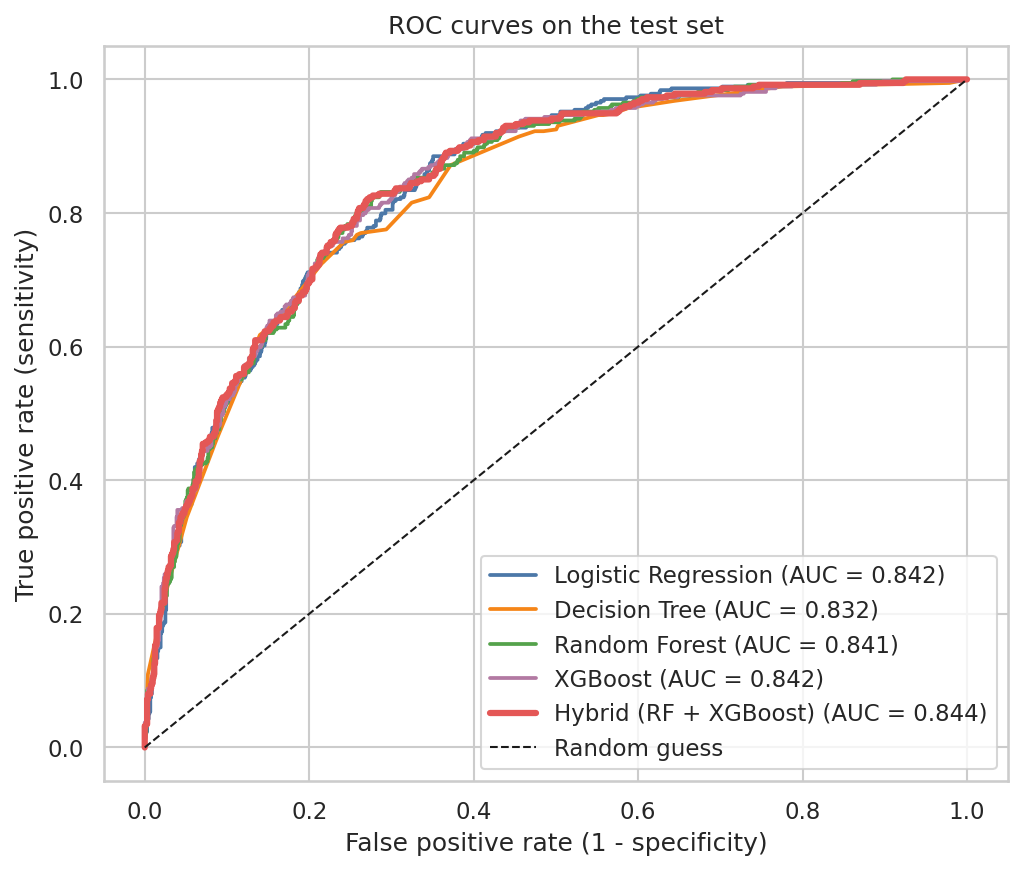

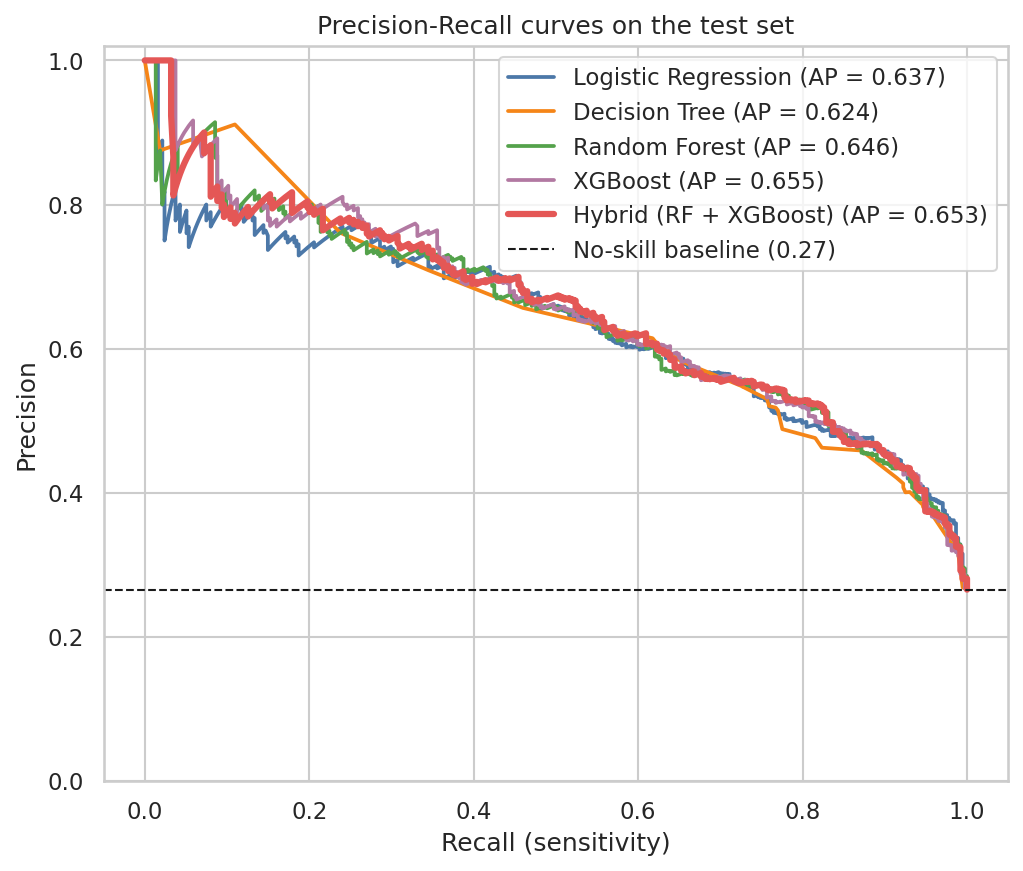

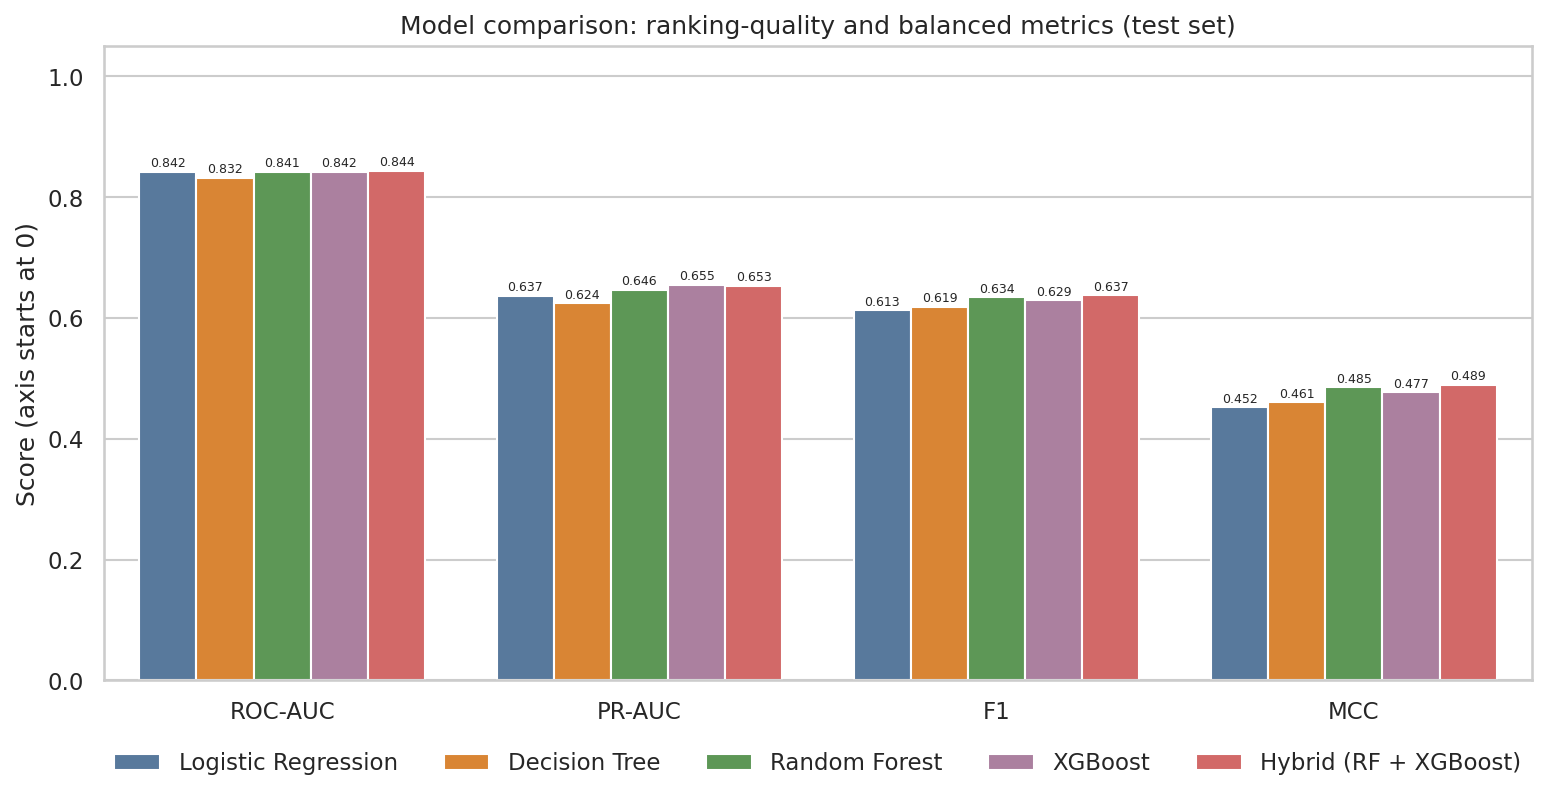

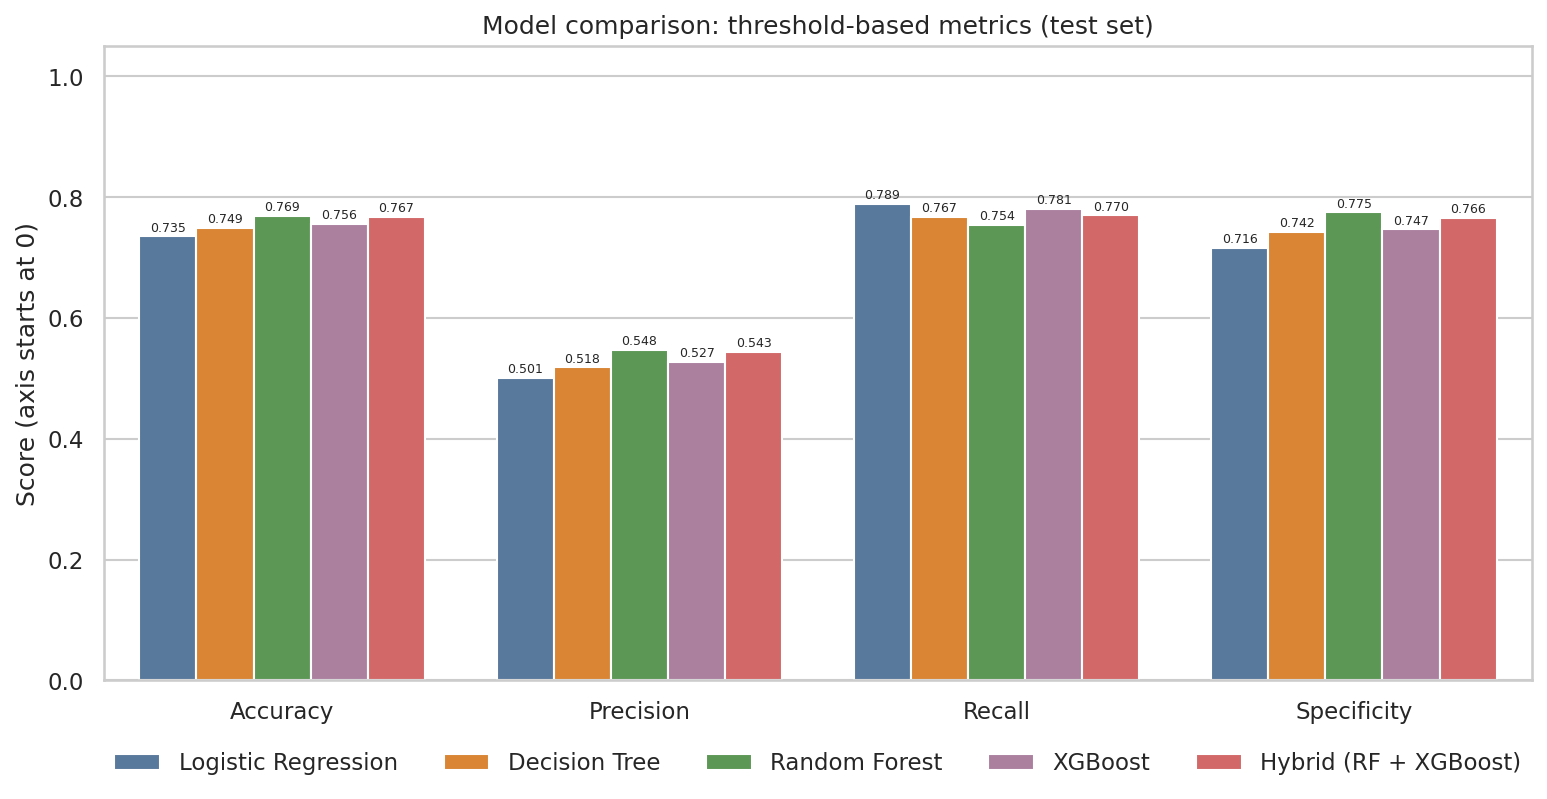

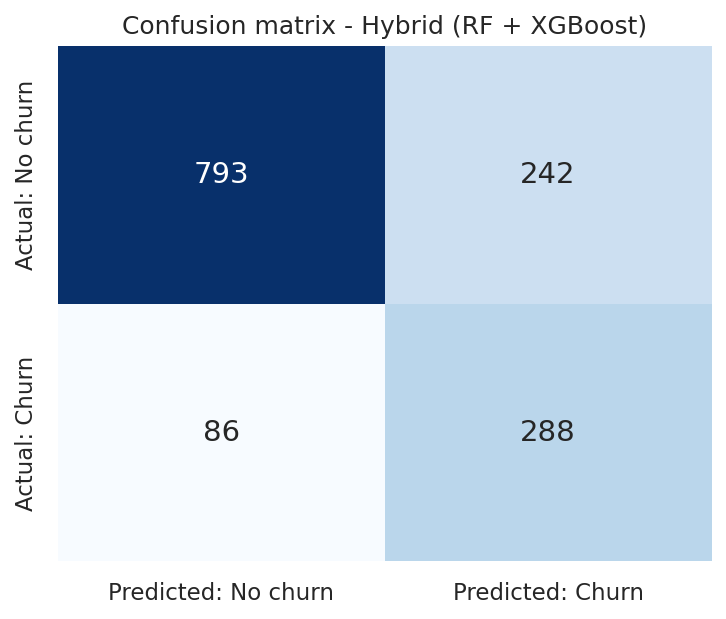

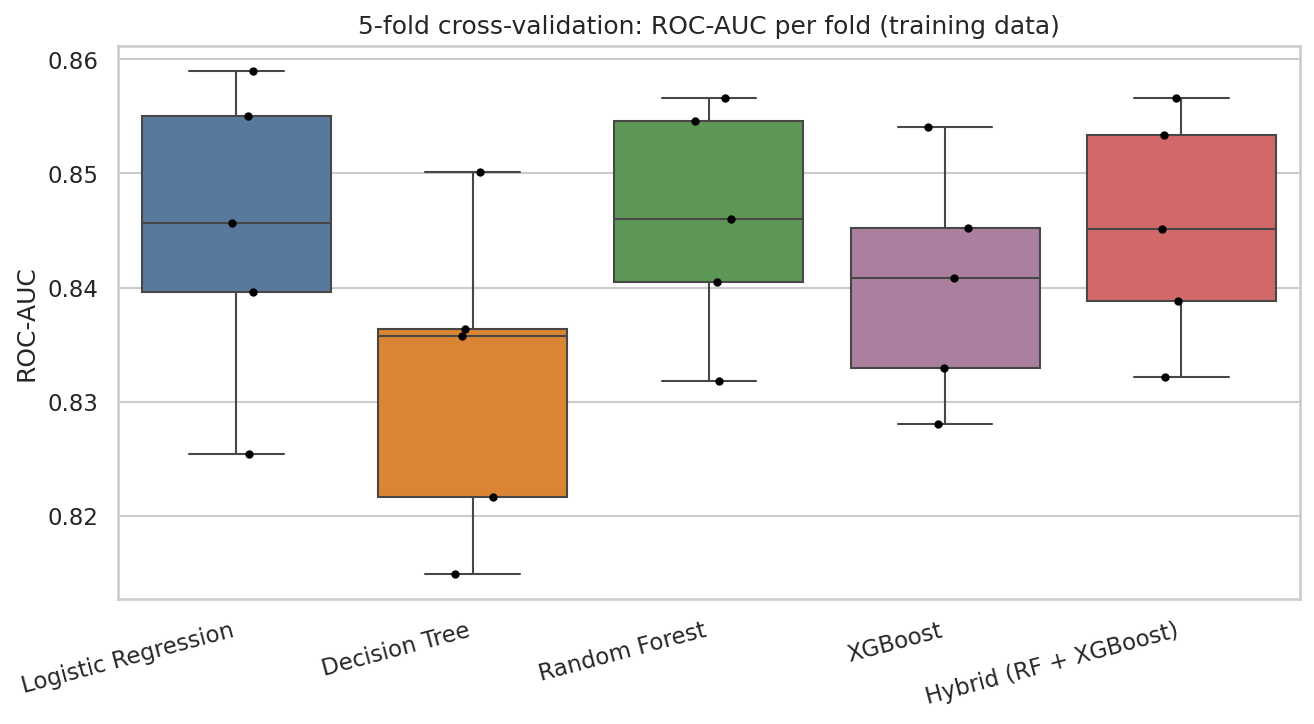

In [6]:
for f in ['07_roc_curves', '08_precision_recall_curves', '09_model_comparison_auc_f1_mcc', '10_model_comparison_accuracy_precision_recall_specificity', '11_confusion_matrix_hybrid', '14_cv_rocauc_boxplot']:
    display(Image(str(config.FIGURES_DIR / f'{f}.png'), width=760))

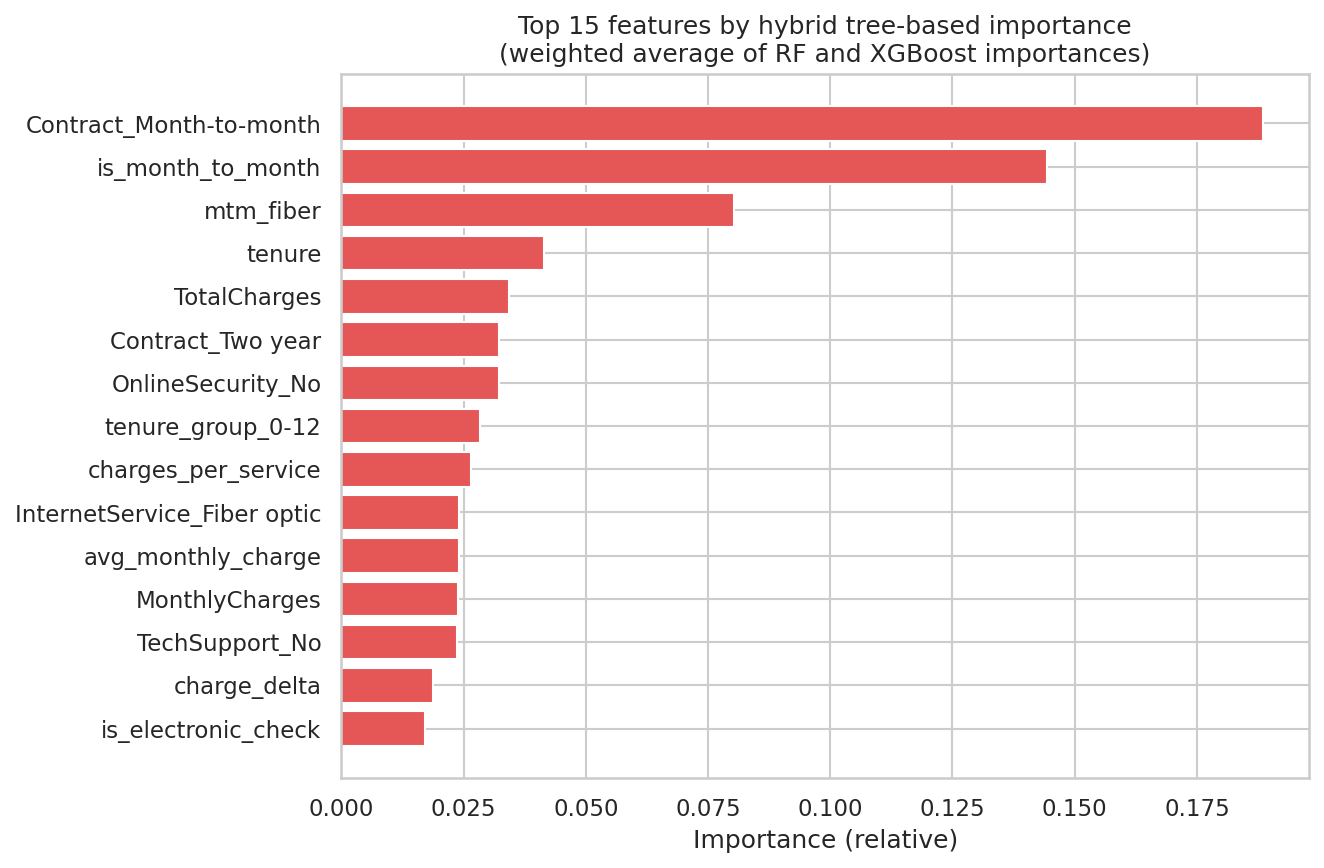

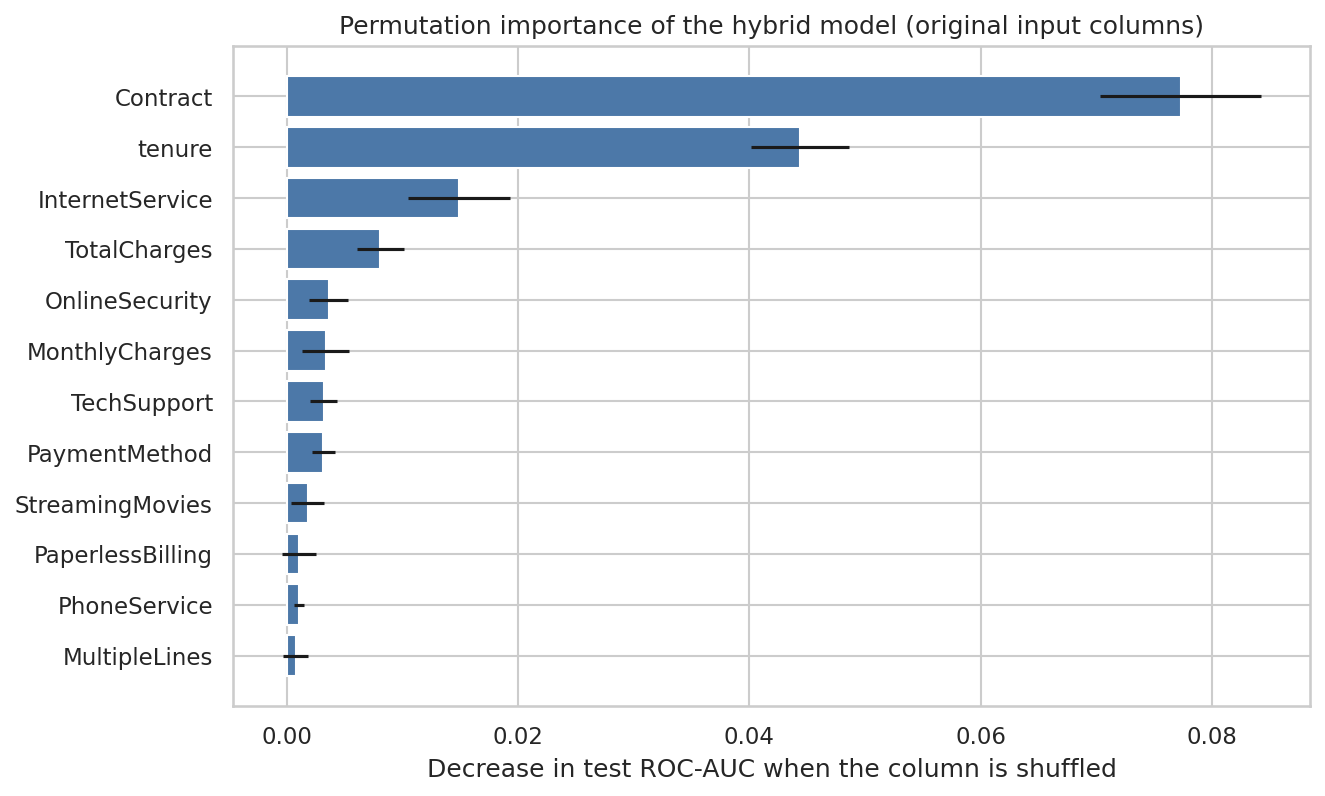

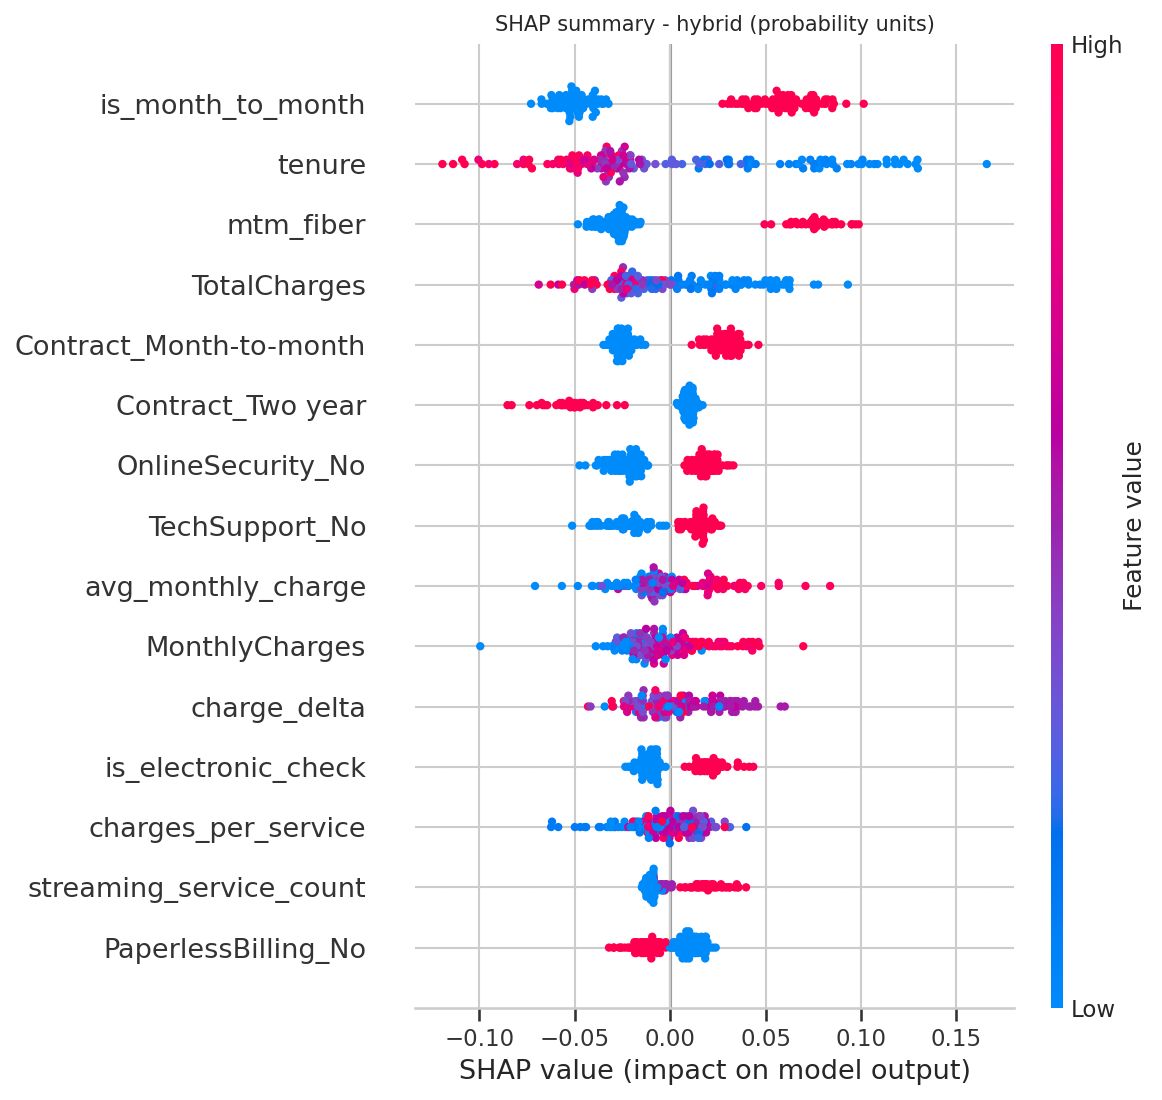

In [7]:
for f in ['12_feature_importance_tree_based', '12b_permutation_importance_hybrid', '13_shap_summary_beeswarm']:
    p = config.FIGURES_DIR / f'{f}.png'
    if p.exists():
        display(Image(str(p), width=700))

**Interpretation guide**: compare the hybrid with each baseline metric by metric; check whether differences exceed the cross-validation standard deviation and the bootstrap confidence intervals before calling any model 'better'.